# Proyek Analisis Data: Air Quality Dataset (Beijing 2013–2017)
- **Nama:** Ezra Migguelle Budi Dharma
- **Email:** ds284b6y0526@student.devacademy.id
- **ID Dicoding:** ezra_migguelle_byhv8

## Menentukan Pertanyaan Bisnis
1. **Pertanyaan 1:** Bagaimana tren rata-rata bulanan konsentrasi polutan PM2.5 dan PM10 serta perbedaan rata-ratanya antar 12 stasiun pemantauan di Beijing selama periode Maret 2013 hingga Februari 2017, dan stasiun mana yang memiliki tingkat PM2.5 tertinggi serta terendah?
   - *Specific*: Fokus pada polutan PM2.5 & PM10 di 12 stasiun Beijing.
   - *Measurable*: Menggunakan rata-rata bulanan dan rata-rata per stasiun dalam satuan $\mu g/m^3$.
   - *Action-Oriented*: Menentukan stasiun prioritas dan bulan kritis untuk mitigasi polusi serta peringatan kesehatan.
   - *Relevant*: PM2.5 dan PM10 merupakan indikator utama kualitas udara yang berdampak langsung pada kesehatan publik.
   - *Time-bound*: Periode Maret 2013 hingga Februari 2017.

2. **Pertanyaan 2:** Seberapa kuat korelasi faktor meteorologi (suhu/`TEMP`, kecepatan angin/`WSPM`, tekanan udara/`PRES`, curah hujan/`RAIN`) terhadap konsentrasi PM2.5, serta pada musim apa konsentrasi PM2.5 mencapai rata-rata tertinggi sepanjang periode 2013–2017?
   - *Specific*: Fokus pada korelasi 4 parameter cuaca dan variasi 4 musim terhadap PM2.5.
   - *Measurable*: Koefisien korelasi Pearson ($r$) dan rata-rata PM2.5 per musim ($\mu g/m^3$).
   - *Action-Oriented*: Menjadi dasar penjadwalan kebijakan pembatasan emisi dan peringatan dini kualitas udara saat musim serta kondisi angin tertentu.
   - *Relevant*: Memahami pendorong cuaca sangat krusial untuk pengendalian dan antisipasi lonjakan polusi udara.
   - *Time-bound*: Periode 2013–2017 (4 siklus musim penuh).

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
print("Semua library berhasil diimpor!")

## Data Wrangling
### Gathering Data
Pada tahap ini, seluruh 12 berkas CSV dari 12 stasiun pemantauan kualitas udara di Beijing (periode 1 Maret 2013 – 28 Februari 2017) dimuat dan digabungkan menjadi satu DataFrame utama.

In [2]:
csv_files = sorted(glob.glob("data/PRSA_Data_*.csv"))
print(f"Jumlah file stasiun ditemukan: {len(csv_files)}")

df_list = [pd.read_csv(file) for file in csv_files]
air_df = pd.concat(df_list, ignore_index=True)

print(f"Dimensi dataset gabungan: {air_df.shape[0]:,} baris dan {air_df.shape[1]} kolom")
print(air_df.head())

Jumlah file stasiun ditemukan: 12
Dimensi dataset gabungan: 420,768 baris dan 18 kolom
   No  year  month  day  hour  PM2.5  PM10   SO2   NO2     CO    O3  TEMP    PRES  DEWP  RAIN   wd  WSPM       station
0   1  2013      3    1     0    4.0   4.0   4.0   7.0  300.0  77.0  -0.7  1023.0 -18.8   0.0  NNW   4.4  Aotizhongxin
1   2  2013      3    1     1    8.0   8.0   4.0   7.0  300.0  77.0  -1.1  1023.2 -18.2   0.0    N   4.7  Aotizhongxin
2   3  2013      3    1     2    7.0   7.0   5.0  10.0  300.0  73.0  -1.1  1023.5 -18.2   0.0  NNW   5.6  Aotizhongxin
3   4  2013      3    1     3    6.0   6.0  11.0  11.0  300.0  72.0  -1.4  1024.5 -19.4   0.0   NW   3.1  Aotizhongxin
4   5  2013      3    1     4    3.0   3.0  12.0  12.0  300.0  72.0  -2.0  1025.2 -19.5   0.0    N   2.0  Aotizhongxin


**Insight Gathering Data:**
- Dataset berhasil digabungkan dari 12 stasiun pemantauan di Beijing (`Aotizhongxin`, `Changping`, `Dingling`, `Dongsi`, `Guanyuan`, `Gucheng`, `Huairou`, `Nongzhanguan`, `Shunyi`, `Tiantan`, `Wanliu`, dan `Wanshouxigong`) dengan total **420.768 baris** observasi per jam dan **18 kolom**.
- Dataset mencakup informasi waktu (`year`, `month`, `day`, `hour`), konsentrasi 6 polutan udara (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), 6 parameter meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`), serta nama stasiun (`station`).

### Assessing Data
Tahap ini bertujuan memeriksa struktur data, tipe data, *missing values*, duplikasi data, serta mendeteksi *outlier* menggunakan parameter statistik dan metode IQR.

In [3]:
print("=== Informasi Struktur & Tipe Data ===")
air_df.info()

print("\n=== Jumlah Missing Values per Kolom ===")
missing = air_df.isnull().sum()
missing_pct = (missing / len(air_df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

print(f"\n=== Jumlah Data Duplikat: {air_df.duplicated().sum()} ===")

=== Informasi Struktur & Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

=== J

In [4]:
print("=== Ringkasan Statistik Deskriptif ===")
print(air_df.describe().round(2))

# Identifikasi outlier menggunakan metode IQR (1.5 * IQR) pada kolom polutan & angin
print("\n=== Deteksi Outlier (Metode IQR 1.5x) ===")
outlier_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'WSPM']
for col in outlier_cols:
    q1 = air_df[col].quantile(0.25)
    q3 = air_df[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    n_out = ((air_df[col] > upper) | (air_df[col] < lower)).sum()
    print(f"{col:6s} | Q1={q1:6.1f} | Q3={q3:6.1f} | Upper Bound={upper:7.1f} | Max={air_df[col].max():7.1f} | Outliers: {n_out:,} ({n_out/len(air_df)*100:.2f}%)")

=== Ringkasan Statistik Deskriptif ===
              No       year      month        day       hour      PM2.5       PM10        SO2        NO2         CO         O3       TEMP       PRES       DEWP       RAIN       WSPM
count  420768.00  420768.00  420768.00  420768.00  420768.00  412029.00  414319.00  411747.00  408652.00  400067.00  407491.00  420370.00  420375.00  420365.00  420378.00  420450.00
mean    17532.50    2014.66       6.52      15.73      11.50      79.79     104.60      15.83      50.64    1230.77      57.37      13.54    1010.75       2.49       0.06       1.73
std     10122.12       1.18       3.45       8.80       6.92      80.82      91.77      21.65      35.13    1160.18      56.66      11.44      10.47      13.79       0.82       1.25
min         1.00    2013.00       1.00       1.00       0.00       2.00       2.00       0.29       1.03     100.00       0.21     -19.90     982.40     -43.40       0.00       0.00
25%      8766.75    2014.00       4.00       8.00  

**Insight Assessing Data (Permasalahan yang Ditemukan & Rencana Cleaning):**
1. **Missing Value:** Terdapat nilai kosong pada 12 kolom (tertinggi pada `CO` sebanyak 20.701 baris / 4,92%, `O3` sebanyak 13.277 baris / 3,16%, `NO2` sebanyak 12.116 baris / 2,88%, hingga `WSPM` sebanyak 318 baris / 0,08%).
   - *Rencana Cleaning:* Karena data polutan dan cuaca bersifat *time-series* per jam pada masing-masing stasiun, penanganan *missing value* numerik dilakukan menggunakan **interpolasi linear (`interpolate`) per stasiun** diikuti `bfill`/`ffill` untuk nilai batas, sedangkan kolom kategoris arah angin (`wd`) diisi dengan **modus (`mode`)** masing-masing stasiun.
2. **Struktur Kolom Waktu & Kolom Redundan:** Informasi waktu masih terpisah pada 4 kolom (`year`, `month`, `day`, `hour`) dan belum bertipe `datetime`, sementara kolom `No` hanya indeks baris yang tidak diperlukan.
   - *Rencana Cleaning:* Menggabungkan 4 kolom waktu menjadi kolom `datetime` bertipe `datetime64`, mengurutkan data berdasarkan `station` dan `datetime`, lalu menghapus kolom `No`.
3. **Outlier pada Polutan:** Berdasarkan metode IQR, terdapat nilai ekstrem di atas ambang batas (misalnya `PM2.5` memiliki 19.142 outlier / 4,55% dengan maksimum 999 $\mu g/m^3$).
   - *Rencana Cleaning:* Pada fenomena kualitas udara di Beijing, lonjakan PM2.5 ekstrem (episode *severe smog*) merupakan kejadian nyata yang krusial bagi analisis kesehatan sehingga tidak di-drop agar tidak menghilangkan informasi krisis polusi; namun tetap dianalisis lebih lanjut melalui pengelompokan kategori *Hazardous*.
4. **Duplicate Data:** Tidak ditemukan data duplikat (`0` baris).

### Cleaning Data
Pada tahap ini, seluruh rencana pembersihan data diterapkan dan diverifikasi kembali (tahap *define, code, test*).

In [5]:
# 1. Buat kolom datetime, urutkan per stasiun & waktu, hapus kolom 'No'
clean_df = air_df.copy()
clean_df['datetime'] = pd.to_datetime(clean_df[['year', 'month', 'day', 'hour']])
clean_df = clean_df.sort_values(['station', 'datetime']).reset_index(drop=True)
clean_df.drop(columns=['No'], inplace=True)

# 2. Interpolasi linear per stasiun untuk kolom numerik time-series
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
for col in num_cols:
    clean_df[col] = clean_df.groupby('station')[col].transform(
        lambda s: s.interpolate(method='linear').bfill().ffill()
    )

# 3. Imputasi modus per stasiun untuk kolom kategoris 'wd' (wind direction)
clean_df['wd'] = clean_df.groupby('station')['wd'].transform(
    lambda s: s.fillna(s.mode()[0])
)

# 4. Feature engineering: menambahkan kolom musim (season) berdasarkan iklim Beijing
def map_season(month):
    if month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    else:
        return 'Winter'

clean_df['season'] = clean_df['month'].apply(map_season)

# Test hasil cleaning
print("Total missing values setelah cleaning:", clean_df.isnull().sum().sum())
print("Total duplikat setelah cleaning:", clean_df.duplicated().sum())
print("Dimensi data bersih:", clean_df.shape)
print(clean_df[['datetime', 'station', 'season', 'PM2.5', 'PM10', 'TEMP', 'WSPM', 'wd']].head())

Total missing values setelah cleaning: 0
Total duplikat setelah cleaning: 0
Dimensi data bersih: (420768, 19)
             datetime       station  season  PM2.5  PM10  TEMP  WSPM   wd
0 2013-03-01 00:00:00  Aotizhongxin  Spring    4.0   4.0  -0.7   4.4  NNW
1 2013-03-01 01:00:00  Aotizhongxin  Spring    8.0   8.0  -1.1   4.7    N
2 2013-03-01 02:00:00  Aotizhongxin  Spring    7.0   7.0  -1.1   5.6  NNW
3 2013-03-01 03:00:00  Aotizhongxin  Spring    6.0   6.0  -1.4   3.1   NW
4 2013-03-01 04:00:00  Aotizhongxin  Spring    3.0   3.0  -2.0   2.0    N


**Insight Cleaning Data:**
- Seluruh *missing values* berhasil dibersihkan (`0` nilai kosong tersisa) tanpa kehilangan satu pun baris observasi (420.768 baris utuh).
- Kolom `datetime` dan `season` (`Spring`, `Summer`, `Autumn`, `Winter`) telah terbentuk untuk mempermudah analisis tren deret waktu dan pola musiman.

## Exploratory Data Analysis (EDA)
### Explore Distribusi Statistik, Stasiun, Tren Waktu, dan Faktor Meteorologi

In [6]:
print("=== Rangkuman Statistik Data Bersih (Termasuk Kategoris) ===")
print(clean_df.describe(include='all').T[['count', 'mean', 'std', 'min', '50%', 'max']])

=== Rangkuman Statistik Data Bersih (Termasuk Kategoris) ===
             count                           mean          std                  min                  50%                  max
year      420768.0                     2014.66256     1.177198               2013.0               2015.0               2017.0
month     420768.0                        6.52293     3.448707                  1.0                  7.0                 12.0
day       420768.0                      15.729637     8.800102                  1.0                 16.0                 31.0
hour      420768.0                           11.5     6.922195                  0.0                 11.5                 23.0
PM2.5     420768.0                      79.839718    80.950217                  2.0                 55.0                999.0
PM10      420768.0                     104.910268    92.431422                  2.0                 82.0                999.0
SO2       420768.0                       15.91309    21.8

In [7]:
# 1. Agregasi PM2.5 dan PM10 berdasarkan stasiun (untuk Pertanyaan 1)
station_summary = clean_df.groupby('station').agg(
    PM25_mean=('PM2.5', 'mean'),
    PM25_median=('PM2.5', 'median'),
    PM25_max=('PM2.5', 'max'),
    PM10_mean=('PM10', 'mean'),
    PM10_median=('PM10', 'median')
).sort_values(by='PM25_mean', ascending=False).round(2)

print("=== Ringkasan PM2.5 dan PM10 per Stasiun ===")
print(station_summary)

=== Ringkasan PM2.5 dan PM10 per Stasiun ===
               PM25_mean  PM25_median  PM25_max  PM10_mean  PM10_median
station                                                                
Dongsi             86.14         61.0     737.0     110.35         86.0
Nongzhanguan       85.08         59.0     844.0     109.38         85.0
Wanshouxigong      85.07         60.0     999.0     112.51         91.0
Gucheng            84.07         60.0     770.0     119.26        100.0
Wanliu             83.47         59.0     957.0     110.71         88.0
Guanyuan           82.90         59.0     680.0     109.37         89.0
Aotizhongxin       82.54         58.0     898.0     110.21         87.0
Tiantan            82.03         58.0     821.0     106.54         85.0
Shunyi             79.44         55.0     941.0      99.27         77.0
Changping          70.99         46.0     882.0      94.79         72.0
Huairou            69.50         47.0     762.0      92.42         69.0
Dingling           

In [8]:
# 2. Tren Tahunan dan Bulanan (untuk Pertanyaan 1)
yearly_summary = clean_df.groupby('year').agg(
    n_months=('month', 'nunique'),
    PM25_mean=('PM2.5', 'mean'),
    PM10_mean=('PM10', 'mean')
).round(2)
print("=== Rata-rata Polutan per Tahun ===")
print(yearly_summary)

monthly_summary = clean_df.groupby('month')[['PM2.5', 'PM10']].mean().round(2)
print("\n=== Rata-rata Polutan per Bulan (Jan-Des) ===")
print(monthly_summary)

=== Rata-rata Polutan per Tahun ===
      n_months  PM25_mean  PM10_mean
year                                
2013        10      79.77     103.20
2014        12      86.18     116.82
2015        12      79.31     103.66
2016        12      72.08      94.75
2017         2      92.41     110.88

=== Rata-rata Polutan per Bulan (Jan-Des) ===
        PM2.5    PM10
month                
1       93.76  113.40
2       89.21  104.63
3       94.59  136.72
4       73.37  117.30
5       63.54  108.48
6       68.84   86.61
7       71.40   84.70
8       53.47   71.46
9       61.28   79.48
10      91.72  112.30
11      93.32  118.08
12     103.68  125.14


In [9]:
# 3. Agregasi Musiman & Korelasi Faktor Meteorologi terhadap PM2.5 (untuk Pertanyaan 2)
season_order = ['Winter', 'Autumn', 'Spring', 'Summer']
season_summary = clean_df.groupby('season').agg(
    PM25_mean=('PM2.5', 'mean'),
    PM25_median=('PM2.5', 'median'),
    PM10_mean=('PM10', 'mean'),
    TEMP_mean=('TEMP', 'mean'),
    WSPM_mean=('WSPM', 'mean'),
    RAIN_mean=('RAIN', 'mean')
).reindex(season_order).round(2)

print("=== Ringkasan Kualitas Udara & Cuaca per Musim ===")
print(season_summary)

corr_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
corr_matrix = clean_df[corr_cols].corr()
print("\n=== Korelasi Variabel terhadap PM2.5 ===")
print(corr_matrix['PM2.5'].sort_values(ascending=False).round(3))

=== Ringkasan Kualitas Udara & Cuaca per Musim ===
        PM25_mean  PM25_median  PM10_mean  TEMP_mean  WSPM_mean  RAIN_mean
season                                                                    
Winter      95.74         56.0     114.69      -0.34       1.90       0.00
Autumn      82.21         55.0     103.39      13.00       1.45       0.06
Spring      77.21         59.0     120.87      15.05       2.07       0.03
Summer      64.52         51.0      80.86      26.15       1.51       0.17

=== Korelasi Variabel terhadap PM2.5 ===
PM2.5    1.000
PM10     0.879
CO       0.780
NO2      0.664
SO2      0.478
DEWP     0.113
PRES     0.020
RAIN    -0.014
TEMP    -0.132
O3      -0.150
WSPM    -0.271
Name: PM2.5, dtype: float64


**Insight Exploratory Data Analysis (EDA):**
- **Perbedaan Antar Stasiun:** Stasiun perkotaan pusat seperti **Dongsi** (rata-rata PM2.5 `86,14 µg/m³`), **Nongzhanguan** (`85,08 µg/m³`), dan **Wanshouxigong** (`85,07 µg/m³`) mencatat tingkat PM2.5 tertinggi. Sebaliknya, stasiun pinggiran utara seperti **Dingling** (`66,85 µg/m³`) dan **Huairou** (`69,50 µg/m³`) jauh lebih bersih.
- **Tren Tahunan & Bulanan:** Untuk tahun dengan 12 bulan penuh (2014–2016), rata-rata PM2.5 menurun secara konsisten dari `86,18 µg/m³` (2014) menjadi `72,08 µg/m³` (2016). Angka 2017 (`92,41 µg/m³`) tampak tinggi karena hanya mencakup 2 bulan puncak musim dingin (Januari–Februari). Secara agregat bulanan, polusi PM2.5 memuncak pada **Desember** (`103,68 µg/m³`) dan terendah pada **Agustus** (`53,47 µg/m³`).
- **Pola Musiman & Meteorologi:** **Winter** memiliki rata-rata PM2.5 tertinggi (`95,74 µg/m³`), jauh di atas **Summer** (`64,52 µg/m³`). Menariknya, **Spring** memiliki rata-rata **PM10** tertinggi (`120,87 µg/m³`), konsisten dengan fenomena badai debu musim semi di Beijing.
- **Korelasi:** Di antara parameter meteorologi, **kecepatan angin (`WSPM`)** memiliki korelasi negatif terkuat terhadap PM2.5 ($r = -0,271$), disusul suhu (`TEMP`, $r = -0,132$). Sementara itu, PM2.5 berkorelasi positif sangat kuat dengan polutan hasil pembakaran lainnya: `PM10` ($r = 0,879$), `CO` ($r = 0,780$), dan `NO2` ($r = 0,664$).

## Visualization & Explanatory Analysis
Seluruh visualisasi dirancang dengan memperhatikan prinsip *Data Ink Ratio*, pelabelan sumbu & judul yang jelas, serta penggunaan warna kontras untuk mengarahkan fokus audiens pada temuan utama.

### Pertanyaan 1: Bagaimana tren rata-rata bulanan PM2.5 & PM10 serta perbandingan antar 12 stasiun di Beijing (2013–2017)?

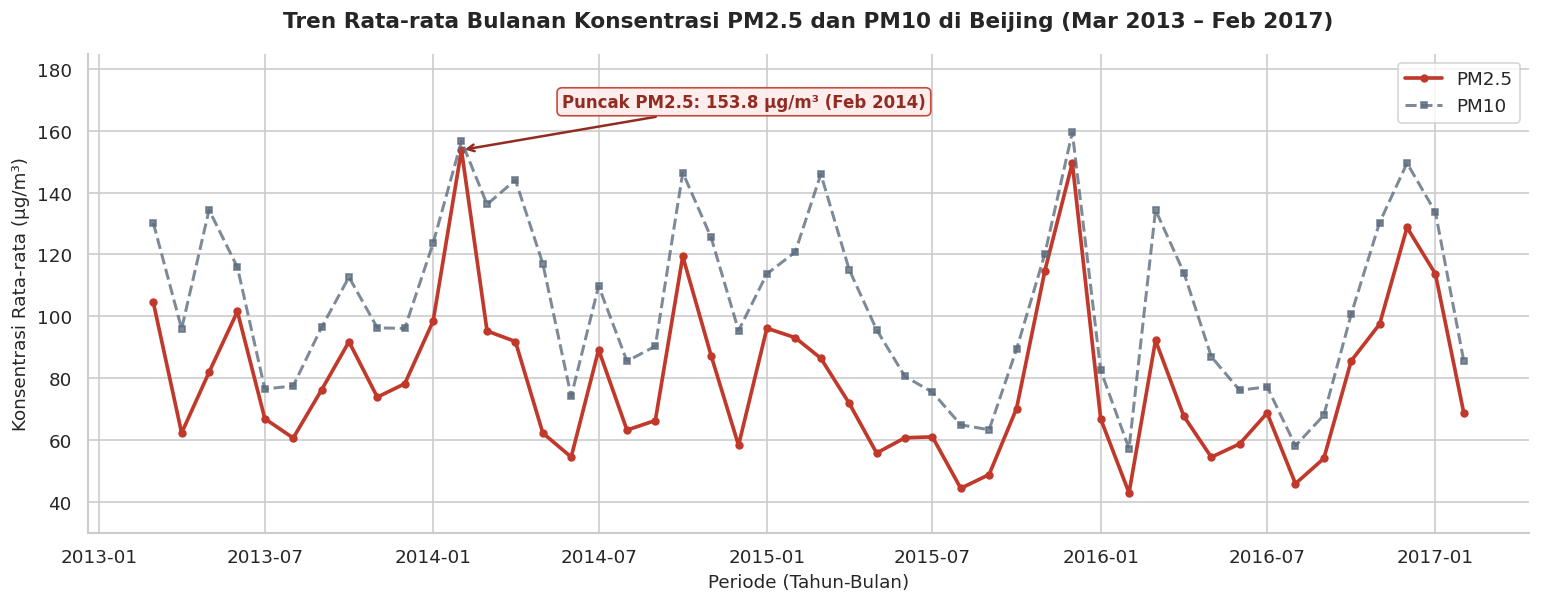

In [10]:
# Visualisasi 1A: Tren Rata-rata Bulanan PM2.5 dan PM10 (Maret 2013 - Februari 2017)
monthly_ts = clean_df.set_index('datetime')[['PM2.5', 'PM10']].resample('MS').mean()

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.plot(monthly_ts.index, monthly_ts['PM2.5'], marker='o', markersize=4, linewidth=2.2, color='#C0392B', label='PM2.5')
ax.plot(monthly_ts.index, monthly_ts['PM10'], marker='s', markersize=3.5, linewidth=1.8, color='#5D6D7E', alpha=0.8, linestyle='--', label='PM10')

# Highlight puncak PM2.5 tertinggi tanpa menabrak judul
peak_date = monthly_ts['PM2.5'].idxmax()
peak_val = monthly_ts['PM2.5'].max()
ax.annotate(
    f"Puncak PM2.5: {peak_val:.1f} µg/m³ ({peak_date.strftime('%b %Y')})",
    xy=(peak_date, peak_val),
    xytext=(peak_date + pd.Timedelta(days=110), peak_val + 14),
    arrowprops=dict(arrowstyle='->', color='#922B21', lw=1.5),
    fontsize=10, fontweight='bold', color='#922B21',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#FDEDEC', edgecolor='#C0392B', alpha=0.9)
)

ax.set_title('Tren Rata-rata Bulanan Konsentrasi PM2.5 dan PM10 di Beijing (Mar 2013 – Feb 2017)', fontsize=13, fontweight='bold', pad=16)
ax.set_xlabel('Periode (Tahun-Bulan)', fontsize=11)
ax.set_ylabel('Konsentrasi Rata-rata (µg/m³)', fontsize=11)
ax.set_ylim(30, 185)
ax.legend(frameon=True, loc='upper right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

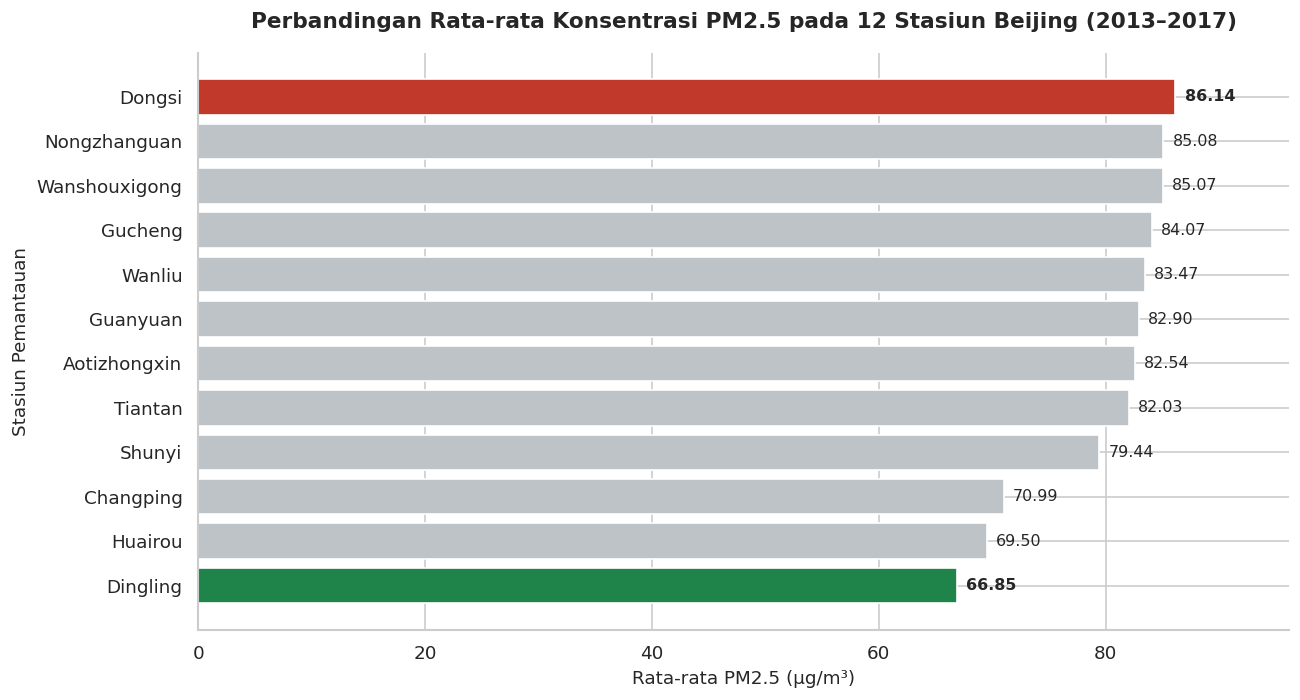

In [11]:
# Visualisasi 1B: Perbandingan Rata-rata PM2.5 di 12 Stasiun Pemantauan
station_pm25 = clean_df.groupby('station')['PM2.5'].mean().sort_values(ascending=True)

colors = []
for st in station_pm25.index:
    if st == station_pm25.index[-1]:
        colors.append('#C0392B')
    elif st == station_pm25.index[0]:
        colors.append('#1E8449')
    else:
        colors.append('#BDC3C7')

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(station_pm25.index, station_pm25.values, color=colors)

for bar in bars:
    width = bar.get_width()
    is_extreme = (width == station_pm25.max()) or (width == station_pm25.min())
    ax.text(width + 0.8, bar.get_y() + bar.get_height()/2, f"{width:.2f}",
            va='center', fontsize=9.5, fontweight='bold' if is_extreme else 'normal')

ax.set_title('Perbandingan Rata-rata Konsentrasi PM2.5 pada 12 Stasiun Beijing (2013–2017)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Rata-rata PM2.5 (µg/m³)', fontsize=11)
ax.set_ylabel('Stasiun Pemantauan', fontsize=11)
ax.set_xlim(0, station_pm25.max() + 10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Seberapa kuat korelasi faktor meteorologi terhadap PM2.5 dan pada musim apa PM2.5 mencapai rata-rata tertinggi?

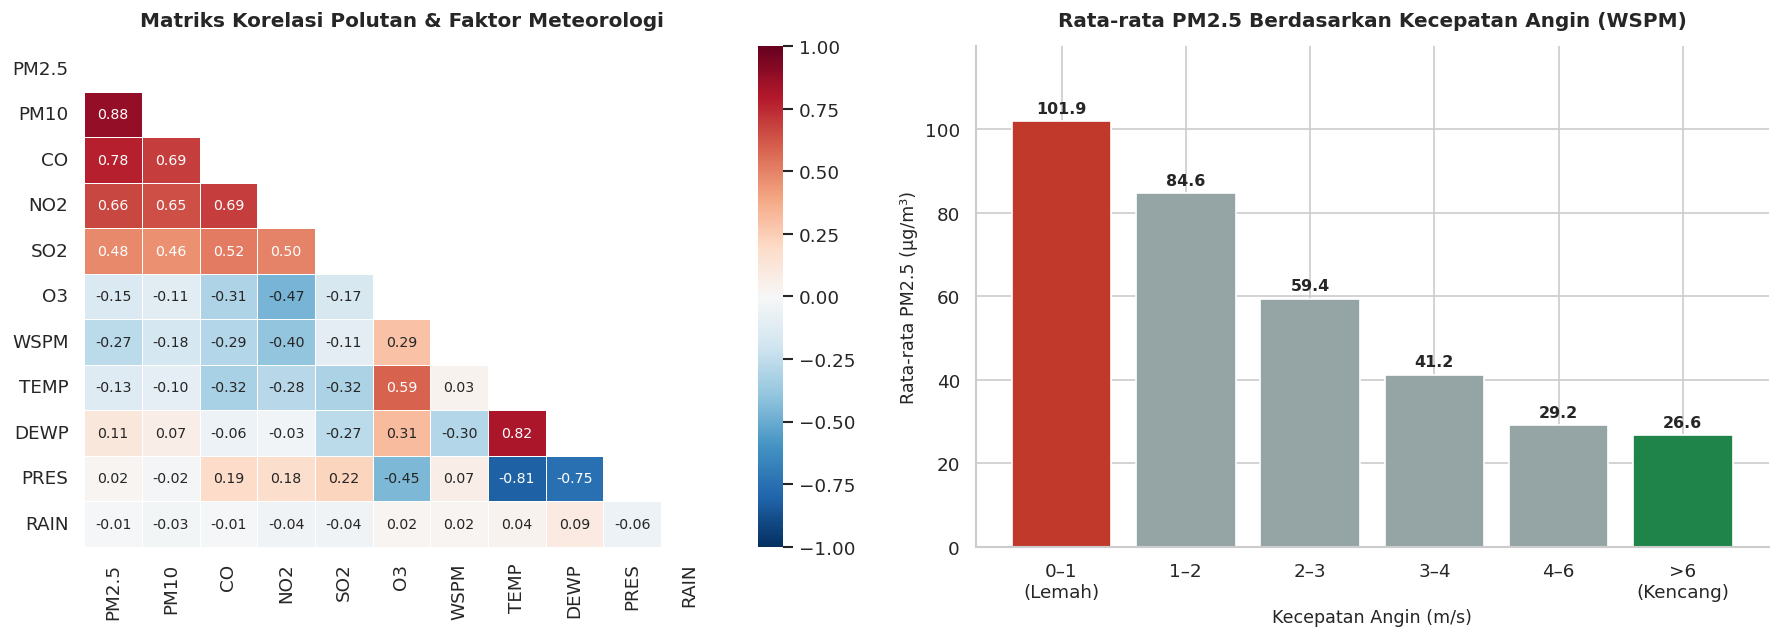

In [12]:
# Visualisasi 2A: Heatmap Korelasi Polutan & Faktor Meteorologi + Hubungan Kecepatan Angin vs PM2.5
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Heatmap Korelasi
meteo_cols = ['PM2.5', 'PM10', 'CO', 'NO2', 'SO2', 'O3', 'WSPM', 'TEMP', 'DEWP', 'PRES', 'RAIN']
corr_mat = clean_df[meteo_cols].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=axes[0], annot_kws={'size': 8.5})
axes[0].set_title('Matriks Korelasi Polutan & Faktor Meteorologi', fontsize=12, fontweight='bold', pad=12)

# Subplot 2: Rata-rata PM2.5 berdasarkan Kategori Kecepatan Angin (WSPM)
wspm_bins = [-0.1, 1.0, 2.0, 3.0, 4.0, 6.0, 15.0]
wspm_labels = ['0–1\n(Lemah)', '1–2', '2–3', '3–4', '4–6', '>6\n(Kencang)']
clean_df['wspm_bin'] = pd.cut(clean_df['WSPM'], bins=wspm_bins, labels=wspm_labels)
wspm_pm = clean_df.groupby('wspm_bin', observed=False)['PM2.5'].mean()

bar_colors = ['#C0392B'] + ['#95A5A6']*4 + ['#1E8449']
bars2 = axes[1].bar(wspm_pm.index, wspm_pm.values, color=bar_colors)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}", ha='center', fontsize=9.5, fontweight='bold')

axes[1].set_title('Rata-rata PM2.5 Berdasarkan Kecepatan Angin (WSPM)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kecepatan Angin (m/s)', fontsize=10.5)
axes[1].set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=10.5)
axes[1].set_ylim(0, wspm_pm.max() + 18)
axes[1].tick_params(axis='x', rotation=0)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

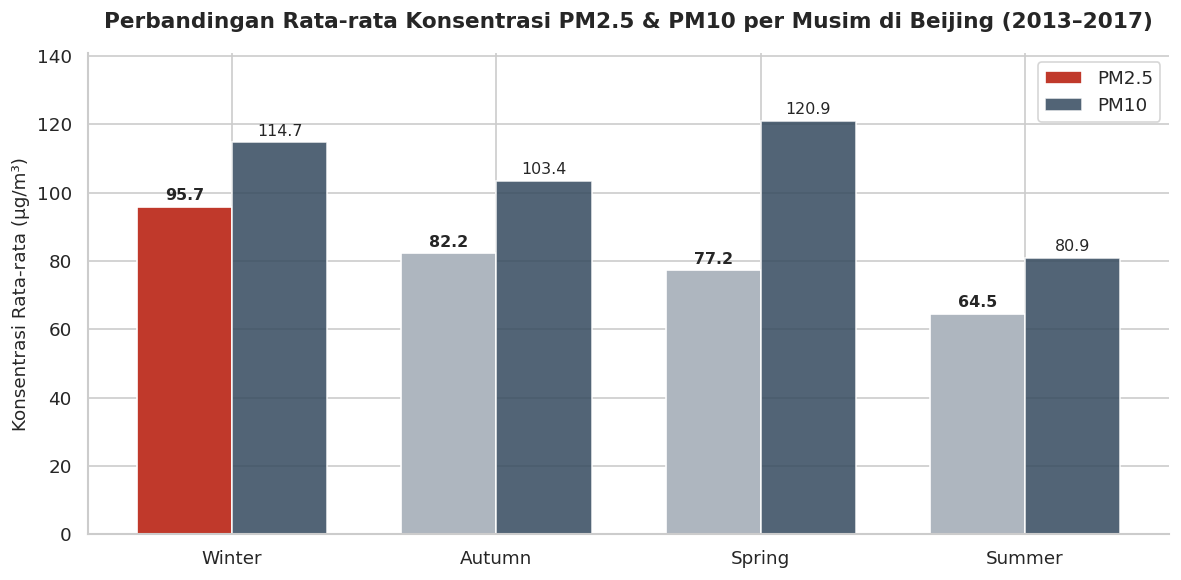

In [13]:
# Visualisasi 2B: Perbandingan Rata-rata PM2.5 dan PM10 Berdasarkan Musim
season_order = ['Winter', 'Autumn', 'Spring', 'Summer']
season_plot = clean_df.groupby('season')[['PM2.5', 'PM10']].mean().reindex(season_order)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(season_order))
width = 0.36

pm25_colors = ['#C0392B', '#AEB6BF', '#AEB6BF', '#AEB6BF']
bars_pm25 = ax.bar(x - width/2, season_plot['PM2.5'], width, label='PM2.5', color=pm25_colors)
bars_pm10 = ax.bar(x + width/2, season_plot['PM10'], width, label='PM10', color='#34495E', alpha=0.85)

for bar in bars_pm25:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}", ha='center', fontsize=9.5, fontweight='bold')
for bar in bars_pm10:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}", ha='center', fontsize=9.5)

ax.set_title('Perbandingan Rata-rata Konsentrasi PM2.5 & PM10 per Musim di Beijing (2013–2017)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(season_order, fontsize=11)
ax.set_ylabel('Konsentrasi Rata-rata (µg/m³)', fontsize=11)
ax.set_ylim(0, season_plot['PM10'].max() + 20)
ax.legend(frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

**Insight Visualization & Explanatory Analysis:**
- **Tren & Siklus Polusi:** Grafik deret waktu memperlihatkan pola musiman berulang setiap tahun dengan lonjakan tajam di musim dingin (puncak tertinggi PM2.5 bulanan terjadi pada **Februari 2014** sebesar `153,8 µg/m³`, diikuti **Desember 2015** sekitar `150 µg/m³`).
- **Kesenjangan Spasial:** Terdapat selisih sebesar **19,29 µg/m³** antara stasiun paling tercemar (**Dongsi**, `86,14 µg/m³`) dan paling bersih (**Dingling**, `66,85 µg/m³`).
- **Peran Kecepatan Angin & Musim:** Ketika kecepatan angin sangat lemah (`0–1 m/s`), rata-rata PM2.5 mencapai `101,9 µg/m³`, namun turun drastis hingga `26,6 µg/m³` saat kecepatan angin melebihi `6 m/s`. Musim **Winter** menjadi periode paling kritis bagi PM2.5 (`95,74 µg/m³`), sedangkan **Spring** menjadi periode tertinggi bagi partikel kasar PM10 (`120,87 µg/m³`).

## Analisis Lanjutan (Opsional): Pengelompokan Kategori Kualitas Udara (Manual Grouping / Binning AQI)
**Tujuan Teknik Analisis:** Menerapkan teknik *binning* (pengelompokan manual berbasis standar ambang batas US EPA untuk PM2.5) guna menerjemahkan angka konsentrasi numerik menjadi kategori risiko kesehatan publik (*Good* hingga *Hazardous*). Teknik ini membantu pemangku kepentingan memahami seberapa sering warga Beijing terpapar udara tidak sehat secara langsung.

=== Distribusi Kategori Kualitas Udara PM2.5 (2013–2017) ===
aqi_category
Good                     15.19
Moderate                 22.12
Unhealthy (Sensitive)    12.95
Unhealthy                34.57
Very Unhealthy           10.68
Hazardous                 4.49
Name: proportion, dtype: float64


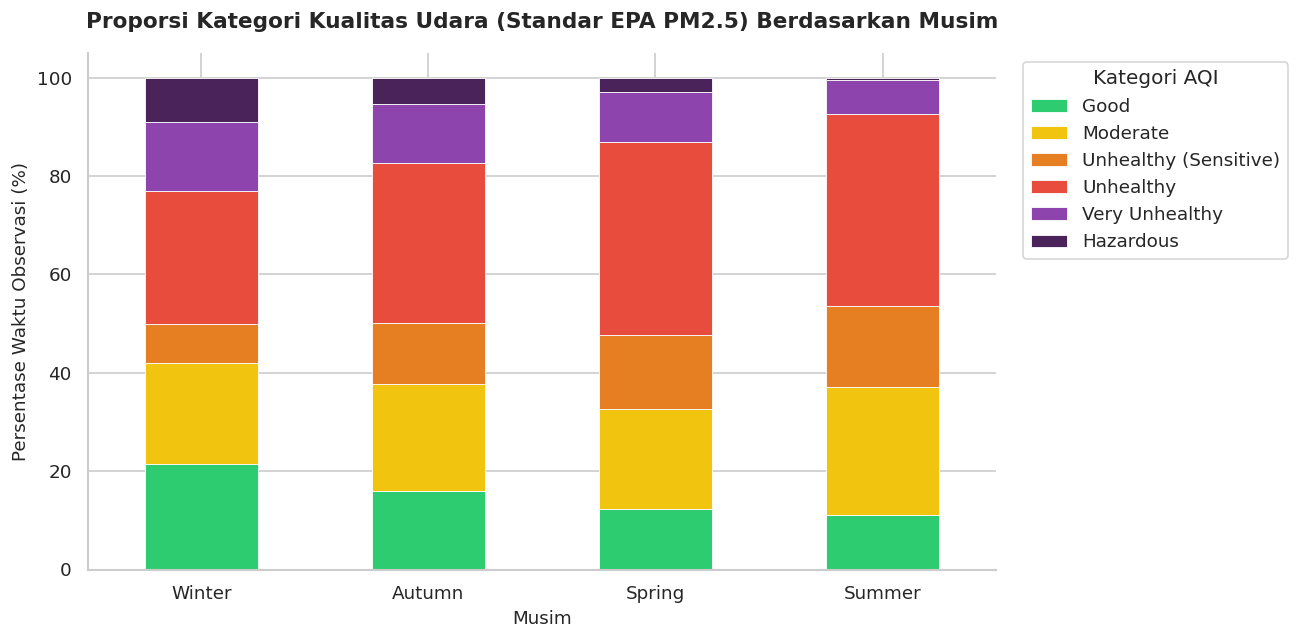

In [14]:
# Binning PM2.5 berdasarkan standar US EPA (µg/m³)
aqi_bins = [-1, 12.0, 35.4, 55.4, 150.4, 250.4, 2000]
aqi_labels = ['Good', 'Moderate', 'Unhealthy (Sensitive)', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
clean_df['aqi_category'] = pd.cut(clean_df['PM2.5'], bins=aqi_bins, labels=aqi_labels)

aqi_dist = (clean_df['aqi_category'].value_counts(normalize=True).reindex(aqi_labels) * 100).round(2)
print("=== Distribusi Kategori Kualitas Udara PM2.5 (2013–2017) ===")
print(aqi_dist)

# Visualisasi Distribusi Kategori AQI per Musim (Stacked Percentage Bar Chart)
season_aqi = pd.crosstab(clean_df['season'], clean_df['aqi_category'], normalize='index').reindex(season_order) * 100

aqi_colors = ['#2ECC71', '#F1C40F', '#E67E22', '#E74C3C', '#8E44AD', '#4A235A']
fig, ax = plt.subplots(figsize=(11, 5.5))
season_aqi.plot(kind='bar', stacked=True, color=aqi_colors, ax=ax, edgecolor='white', linewidth=0.5)

ax.set_title('Proporsi Kategori Kualitas Udara (Standar EPA PM2.5) Berdasarkan Musim', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Musim', fontsize=11)
ax.set_ylabel('Persentase Waktu Observasi (%)', fontsize=11)
ax.set_xticklabels(season_order, rotation=0, fontsize=11)
ax.legend(title='Kategori AQI', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan (Binning AQI):**
- Secara keseluruhan sepanjang 2013–2017, **49,74%** dari seluruh jam observasi berada dalam kategori **Unhealthy hingga Hazardous** (`Unhealthy`: 34,57%, `Very Unhealthy`: 10,68%, `Hazardous`: 4,49%), sementara hanya **15,19%** yang tergolong **Good**.
- Pada musim **Winter**, proporsi jam dalam kategori **Very Unhealthy** dan **Hazardous** meningkat signifikan dibandingkan musim lainnya, mempertegas urgensi sistem peringatan dini kesehatan di bulan November–Februari.

## Export Data Bersih untuk Dashboard Streamlit
Untuk menjaga *load time* dashboard tetap cepat dan responsif, data bersih per jam (420.768 baris) diagregasi menjadi data harian per stasiun (~17.532 baris) beserta kategori AQI harian, lalu disimpan sebagai `dashboard/main_data.csv`.

In [15]:
clean_df['date'] = clean_df['datetime'].dt.date
daily_df = clean_df.groupby(['date', 'year', 'month', 'season', 'station'], as_index=False).agg({
    'PM2.5': 'mean',
    'PM10': 'mean',
    'SO2': 'mean',
    'NO2': 'mean',
    'CO': 'mean',
    'O3': 'mean',
    'TEMP': 'mean',
    'PRES': 'mean',
    'DEWP': 'mean',
    'RAIN': 'sum',
    'WSPM': 'mean'
})

daily_df['aqi_category'] = pd.cut(daily_df['PM2.5'], bins=aqi_bins, labels=aqi_labels)
daily_df.to_csv('dashboard/main_data.csv', index=False)
print(f"File dashboard/main_data.csv berhasil disimpan! Dimensi: {daily_df.shape}")

File dashboard/main_data.csv berhasil disimpan! Dimensi: (17532, 17)


## Conclusion & Recommendation

### Conclusion
1. **Kesimpulan Pertanyaan 1 (Tren Bulanan & Perbandingan Antar Stasiun):**
   - Konsentrasi polutan PM2.5 dan PM10 di Beijing sepanjang Maret 2013 hingga Februari 2017 menunjukkan pola siklus musiman yang konsisten dengan lonjakan tajam pada periode musim dingin (rekor bulanan tertinggi PM2.5 pada **Februari 2014** sebesar `153,8 µg/m³` diikuti **Desember 2015** sekitar `150 µg/m³`; secara agregat bulanan, **Desember** tertinggi di `103,68 µg/m³` dan **Agustus** terendah di `53,47 µg/m³`). Untuk tahun dengan cakupan 12 bulan penuh (2014–2016), rata-rata PM2.5 menunjukkan tren perbaikan dari `86,18 µg/m³` menjadi `72,08 µg/m³`.
   - Secara spasial, stasiun perkotaan pusat **Dongsi** mencatat rata-rata PM2.5 tertinggi (`86,14 µg/m³`), diikuti **Nongzhanguan** (`85,08 µg/m³`) dan **Wanshouxigong** (`85,07 µg/m³`), sedangkan stasiun pinggiran utara **Dingling** mencatat rata-rata terendah (`66,85 µg/m³`).

2. **Kesimpulan Pertanyaan 2 (Korelasi Meteorologi & Pola Musiman):**
   - Di antara faktor meteorologi, **kecepatan angin (`WSPM`)** memiliki korelasi negatif terkuat terhadap PM2.5 ($r = -0,271$), di mana kondisi angin lemah (`0–1 m/s`) menyebabkan penumpukan polutan hingga rata-rata `101,9 µg/m³`, sedangkan angin kencang (`>6 m/s`) menurunkannya hingga `26,6 µg/m³`. Suhu (`TEMP`) juga berkorelasi negatif ($r = -0,132$), sedangkan PM2.5 berkorelasi positif sangat kuat dengan `PM10` ($r = 0,879$), `CO` ($r = 0,780$), dan `NO2` ($r = 0,664$).
   - **Winter (Musim Dingin)** merupakan musim dengan konsentrasi PM2.5 tertinggi (`95,74 µg/m³`), jauh lebih tinggi dibandingkan **Summer** (`64,52 µg/m³`). Sementara itu, **Spring** mencatat rata-rata PM10 tertinggi (`120,87 µg/m³`). Hasil analisis binning AQI mengonfirmasi bahwa **49,74%** observasi berada pada kategori *Unhealthy* hingga *Hazardous*.

### Recommendation (Action Items)
1. **Penjadwalan Kebijakan Emisi & Peringatan Dini Berbasis Cuaca:** Pemerintah daerah dan dinas lingkungan hidup perlu memprioritaskan pembatasan emisi kendaraan bermotor serta transisi pemanas berbahan bakar batu bara secara ketat mulai **Oktober hingga Februari (Autumn–Winter)**, khususnya saat prakiraan cuaca menunjukkan kecepatan angin lemah (`<2 m/s`).
2. **Fokus Intervensi di Zona Perkotaan Pusat:** Prioritaskan penambahan ruang terbuka hijau, pengawasan emisi industri/lalu lintas, serta penyediaan fasilitas peringatan kualitas udara publik di area sekitar stasiun **Dongsi**, **Nongzhanguan**, dan **Wanshouxigong** yang secara konsisten berada pada peringkat polusi tertinggi.
3. **Mitigasi Partikel Kasar (PM10) di Musim Semi:** Terapkan penyiraman jalan raya berkala dan pengendalian debu proyek konstruksi selama **Maret–Mei (Spring)** untuk menekan lonjakan PM10 yang memuncak di musim semi.